# Домашнее задание 4. Сравнительные преимущества и экономическая сложность

**Оценивание.** `Неделя 4_НС_Поиск экспортных рынков_ДЗ.ipynb` весит 50% оценки. PDF-отчёт также весит 50% оценки. Максимальный балл за домашнее задание составляет 10 баллов.
**Пояснение к разбалловке.** В предмете нет официального деления на уровни сложности. Цвета лишь помогают ориентироваться в заданиях. За все пункты синего уровня можно получить максимум 5 баллов из 10. Пункты синего и красного уровней дают максимум 7 баллов из 10. Пункты всех трёх уровней дают максимум 10 баллов из 10. Максимальный балл за домашнее задание составляет 10 баллов. Бонусный пункт 3г даёт 1 дополнительный балл чёрного уровня, но итоговый балл за домашнее задание всё равно не может превышать 10.

В этом блокноте ты выполняешь только техническую часть. Рассчитай альтернативные издержки в учебном примере, загрузи торговые данные, рассчитай показатели сравнительных преимуществ и экономической сложности. Интерпретацию, аргументы и итоговое решение пиши в PDF-отчёте, ссылаясь на результаты этого блокнота.

В прикладной части ты работаешь с одним российским товаром и одной версией классификации HS. Не меняй объект анализа, версию HS и период между пунктами без объяснения.

## Для работы тебе пригодятся

Лонгрид недели 4 нужен как справочник по альтернативным издержкам, сравнительным преимуществам, RCA и экономической сложности. Учебные пункты 1а–1в помогают отделить абсолютное преимущество от сравнительного и увидеть, как мировая относительная цена задаёт границы специализации.

В прикладных пунктах ты перенесёшь эту логику на реальные данные BACI и показатели OEC: сначала рассчитаешь RCA, затем проверишь его динамику, концентрацию экспортной корзины и связь с ECI и PCI. Если будет непонятно, что означает показатель, вернись к соответствующему разделу лонгрида и обязательно проверь числитель, знаменатель, год и уровень HS.

Аналитическую часть оформи в LaTeX и сдай PDF-отчёт, полученный после компиляции. Вместе с ним сдай заполненный блокнот `.ipynb`; исходный `.tex` сдавать не нужно.


In [1]:
# Запусти эту ячейку перед выполнением заданий.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

pd.options.display.float_format = "{:,.3f}".format


**[Синий, 1 балл]**

## Пункт 1а. Альтернативные издержки и сравнительные преимущества

Север может за месяц произвести либо 100 единиц текстиля, либо 50 единиц электроники. Юг может произвести либо 60 единиц текстиля, либо 60 единиц электроники. Построй таблицу альтернативных издержек обоих товаров. По ней определи сравнительное преимущество каждой страны.

**Что должно получиться.** Таблица производственных возможностей и альтернативных издержек. После таблицы нужен короткий вывод.

**Пример вывода**

```text
Север  OC(E)=... T  OC(T)=... E
Юг     OC(E)=... T  OC(T)=... E
Сравнительное преимущество  Север — ..., Юг — ...
```

In [2]:
# Сколько страна производит за месяц, если делает только один товар
ppf = pd.DataFrame({
    "Страна": ["Север", "Юг"],
    "Текстиль_макс": [100, 60],
    "Электроника_макс": [50, 60],
})

# Альтернативные издержки: сколько единиц другого товара теряем ради одной единицы этого
ppf["OC(E), ед. текстиля"] = ppf["Текстиль_макс"] / ppf["Электроника_макс"]
ppf["OC(T), ед. электроники"] = ppf["Электроника_макс"] / ppf["Текстиль_макс"]
display(ppf)

# Проверка: в каждой стране издержки двух товаров взаимно обратны
print("OC(E) * OC(T):", (ppf["OC(E), ед. текстиля"] * ppf["OC(T), ед. электроники"]).tolist())
print()

north = ppf.iloc[0]
south = ppf.iloc[1]

for _, row in ppf.iterrows():
    print(f"{row['Страна']:6} OC(E)={row['OC(E), ед. текстиля']:.1f} T  OC(T)={row['OC(T), ед. электроники']:.1f} E")

if north["OC(T), ед. электроники"] < south["OC(T), ед. электроники"]:
    textile_country = "Север"
else:
    textile_country = "Юг"
if north["OC(E), ед. текстиля"] < south["OC(E), ед. текстиля"]:
    electronics_country = "Север"
else:
    electronics_country = "Юг"

print(f"Сравнительное преимущество  {textile_country} - текстиль, {electronics_country} - электроника")
print("Текстиль дешевле обходится Северу: 0.5 E за единицу против 1 E у Юга,")
print("а электроника дешевле Югу: 1 T за единицу против 2 T у Севера")

,Страна,Текстиль_макс,Электроника_макс,"OC(E), ед. текстиля","OC(T), ед. электроники"
0,Север,100,50,2.000,0.500
1,Юг,60,60,1.000,1.000


OC(E) * OC(T): [1.0, 1.0]

Север  OC(E)=2.0 T  OC(T)=0.5 E
Юг     OC(E)=1.0 T  OC(T)=1.0 E
Сравнительное преимущество  Север - текстиль, Юг - электроника
Текстиль дешевле обходится Северу: 0.5 E за единицу против 1 E у Юга,
а электроника дешевле Югу: 1 T за единицу против 2 T у Севера


**[Синий, 1 балл]**

## Пункт 1б. Мировая относительная цена равна единице

Построй границы производственных возможностей обеих стран. Добавь линии стоимости выпуска для $P_E/P_T=1$. Определи производственный выбор Севера и Юга. Объясни, почему у одной из стран множество выпусков максимизирует стоимость производства. Не привлекай предпочтения для объяснения производственного выбора.

**Что должно получиться.** Два графика с одинаковыми осями и вывод о производственном выборе.

**Пример вывода**

```text
Производство Севера  ...
Производство Юга     ...
Выбор Юга  единственен / не единственен, потому что ...
```

Север: только текстиль = 100 ед. T, только электроника = 50 ед. T
Юг: только текстиль = 60 ед. T, только электроника = 60 ед. T


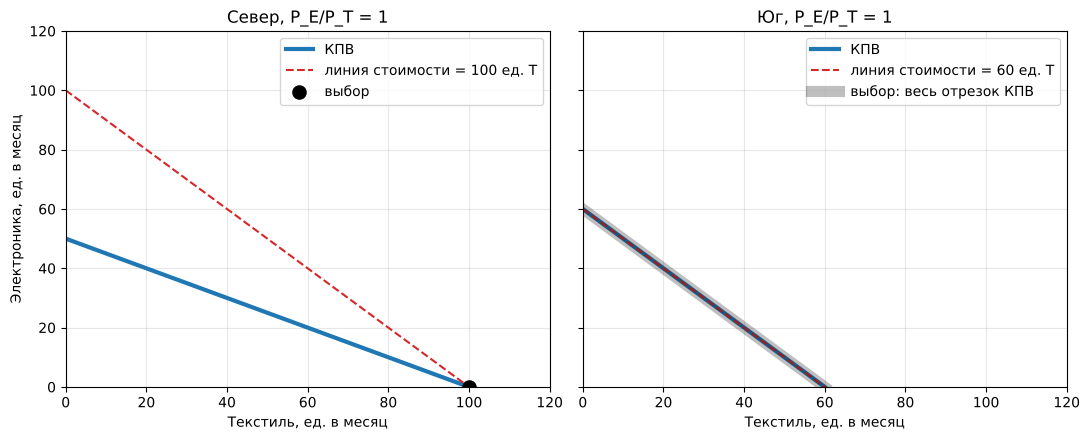

Производство Севера  только текстиль, 100 T
Производство Юга     любая точка на КПВ
Выбор Юга  не единственен, потому что цена 1 равна его OC(E) = 1:
линия стоимости совпадает с КПВ, и любая точка на ней даёт одну и ту же стоимость 60 ед. T


In [3]:
def output_value(textile, electronics, p):
    # стоимость выпуска в единицах текстиля, p = P_E / P_T
    return textile + p * electronics


def best_output(t_max, e_max, p):
    value_t = output_value(t_max, 0, p)
    value_e = output_value(0, e_max, p)
    if value_t > value_e:
        return "только текстиль", value_t
    if value_e > value_t:
        return "только электроника", value_e
    return "любая точка на КПВ", value_t


def plot_choice(p):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True, sharey=True)
    t = np.linspace(0, 120, 100)
    for ax, (_, row) in zip(axes, ppf.iterrows()):
        t_max = row["Текстиль_макс"]
        e_max = row["Электроника_макс"]
        choice, value = best_output(t_max, e_max, p)
        ax.plot([0, t_max], [e_max, 0], lw=3, label="КПВ")
        ax.plot(t, (value - t) / p, "--", color="tab:red", label=f"линия стоимости = {value:.0f} ед. T")
        if choice == "только текстиль":
            ax.scatter([t_max], [0], s=90, color="black", zorder=3, label="выбор")
        elif choice == "только электроника":
            ax.scatter([0], [e_max], s=90, color="black", zorder=3, label="выбор")
        else:
            ax.plot([0, t_max], [e_max, 0], lw=8, color="black", alpha=0.25, label="выбор: весь отрезок КПВ")
        ax.set_title(f"{row['Страна']}, P_E/P_T = {p}")
        ax.set_xlabel("Текстиль, ед. в месяц")
        ax.set_xlim(0, 120)
        ax.set_ylim(0, 120)
        ax.grid(alpha=0.3)
        ax.legend(loc="upper right")
    axes[0].set_ylabel("Электроника, ед. в месяц")
    plt.tight_layout()
    plt.show()


p = 1
for _, row in ppf.iterrows():
    v_t = output_value(row["Текстиль_макс"], 0, p)
    v_e = output_value(0, row["Электроника_макс"], p)
    print(f"{row['Страна']}: только текстиль = {v_t:.0f} ед. T, только электроника = {v_e:.0f} ед. T")

plot_choice(p)

north_choice = best_output(north["Текстиль_макс"], north["Электроника_макс"], p)[0]
south_choice = best_output(south["Текстиль_макс"], south["Электроника_макс"], p)[0]
print(f"Производство Севера  {north_choice}, 100 T")
print(f"Производство Юга     {south_choice}")
print("Выбор Юга  не единственен, потому что цена 1 равна его OC(E) = 1:")
print("линия стоимости совпадает с КПВ, и любая точка на ней даёт одну и ту же стоимость 60 ед. T")

**[Синий, 1 балл]**

## Пункт 1в. Рост мировой относительной цены электроники

Повтори графический анализ для $P_E/P_T=1{,}5$. Определи производственный выбор каждой страны и потенциальное направление обмена. Отдели вывод о производстве от вывода о потреблении. Объясни, что можно установить по относительной цене, а для чего нужны предпочтения.

**Что должно получиться.** Два графика и сопоставление цены с внутренними альтернативными издержками.

**Пример вывода**

```text
... < ... < ...
Производство Севера  ...
Производство Юга     ...
Потенциальный обмен  ... на ...
```

1.0 (OC(E) Юга) < 1.5 (P_E/P_T) < 2.0 (OC(E) Севера)
Север: только текстиль = 100 ед. T, только электроника = 75 ед. T
Юг: только текстиль = 60 ед. T, только электроника = 90 ед. T


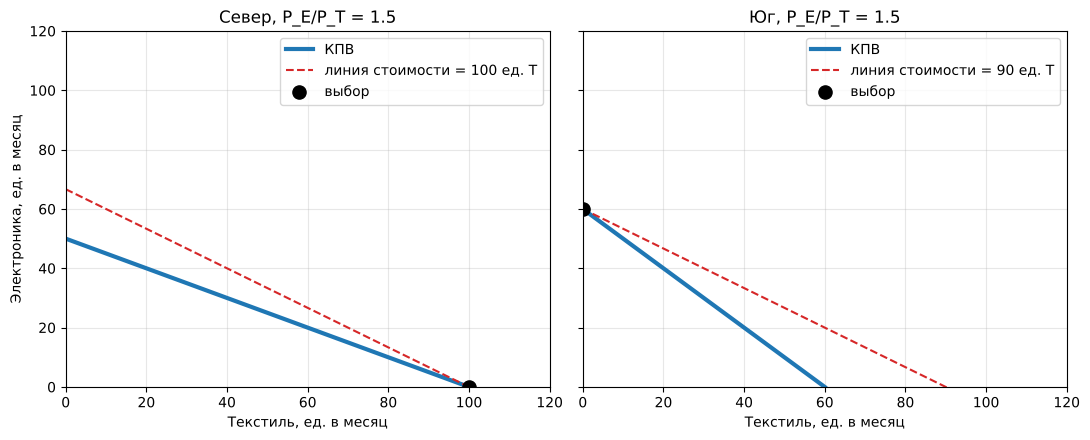

Производство Севера  только текстиль, 100 T
Производство Юга     только электроника, 60 E
Потенциальный обмен  Север продаёт текстиль, Юг продаёт электронику
Цена определила только выпуск. Какой набор каждая страна потребит и сколько обменяет, без предпочтений не сказать


In [4]:
p = 1.5
print(f"{south['OC(E), ед. текстиля']:.1f} (OC(E) Юга) < {p} (P_E/P_T) < {north['OC(E), ед. текстиля']:.1f} (OC(E) Севера)")
for _, row in ppf.iterrows():
    v_t = output_value(row["Текстиль_макс"], 0, p)
    v_e = output_value(0, row["Электроника_макс"], p)
    print(f"{row['Страна']}: только текстиль = {v_t:.0f} ед. T, только электроника = {v_e:.0f} ед. T")

plot_choice(p)

north_choice = best_output(north["Текстиль_макс"], north["Электроника_макс"], p)[0]
south_choice = best_output(south["Текстиль_макс"], south["Электроника_макс"], p)[0]
print(f"Производство Севера  {north_choice}, 100 T")
print(f"Производство Юга     {south_choice}, 60 E")
print("Потенциальный обмен  Север продаёт текстиль, Юг продаёт электронику")
print("Цена определила только выпуск. Какой набор каждая страна потребит и сколько обменяет, без предпочтений не сказать")

**[Синий, 1 балл]**

## Пункт 2а. Паспорт данных и RCA

Используй реальные данные BACI, доступные через API OEC. Зафиксируй страну, товар, HS-код, версию классификации, период и единицы измерения. Для последнего года загрузи четыре величины, входящие в формулу RCA. Рассчитай показатель по формуле

$$
RCA_{cp}=
\frac{X_{cp}/X_c}{X_{wp}/X_w}.
$$

**Что должно получиться.** Таблица четырёх величин из формулы и итоговый RCA.

**Пример вывода**

```text
Год ...
Экспорт товара из страны        ... млн долл.
Весь экспорт страны             ... млрд долл.
Мировой экспорт товара          ... млрд долл.
Весь мировой экспорт            ... трлн долл.
RCA                              ...
```

In [5]:
base_url = "https://api-v2.oec.world/tesseract/data.jsonrecords"
trade_cube = "trade_i_baci_a_17"  # BACI в классификации HS 2017
country_id = "rus"
product_id = "441233"
last_year = 2024


def load_oec(cube, drilldowns, measures, include=None):
    params = {
        "cube": cube,
        "drilldowns": ",".join(drilldowns),
        "measures": ",".join(measures),
        "locale": "en",
    }
    if include is not None:
        params["include"] = ";".join(include)
    r = requests.get(base_url, params=params, timeout=300)
    r.raise_for_status()
    return pd.DataFrame(r.json()["data"]), r.url


# Четыре величины из формулы RCA сразу по всем годам, пригодятся в 2б
x_cp, url_cp = load_oec(trade_cube, ["Year"], ["Trade Value"],
                        [f"Exporter Country Official:{country_id}", f"HS6 Official:{product_id}"])
x_c, url_c = load_oec(trade_cube, ["Year"], ["Trade Value"], [f"Exporter Country Official:{country_id}"])
x_wp, url_wp = load_oec(trade_cube, ["Year"], ["Trade Value"], [f"HS6 Official:{product_id}"])
x_w, url_w = load_oec(trade_cube, ["Year"], ["Trade Value"])

# Весь экспорт фанеры 4412 из России - чтобы связать с прошлым ДЗ
x_4412, url_4412 = load_oec(trade_cube, ["Year"], ["Trade Value"],
                            [f"Exporter Country Official:{country_id}", "HS4 Official:4412"])

rca = x_cp.rename(columns={"Trade Value": "X_cp"})
rca = rca.merge(x_c.rename(columns={"Trade Value": "X_c"}), on="Year")
rca = rca.merge(x_wp.rename(columns={"Trade Value": "X_wp"}), on="Year")
rca = rca.merge(x_w.rename(columns={"Trade Value": "X_w"}), on="Year")
rca = rca.merge(x_4412.rename(columns={"Trade Value": "X_c_4412"}), on="Year")
rca["RCA"] = (rca["X_cp"] / rca["X_c"]) / (rca["X_wp"] / rca["X_w"])

print("Страна: Россия (Russia)")
print("Товар: фанера из листов не толще 6 мм с наружным слоем из лиственных пород - берёза, бук, ольха, тополь и др.")
print("       (Plywood with at least one outer ply of non-coniferous wood: birch, beech, alder, poplar etc.)")
print("HS-код: 441233, уровень HS6, версия HS 2017")
print("Источник: BACI (CEPII) через API OEC, куб trade_i_baci_a_17")
print(f"Период: {rca['Year'].min()}–{rca['Year'].max()}, единицы: доллары США в текущих ценах")
row_last = rca[rca["Year"] == last_year].iloc[0]
print(f"Доля 441233 во всём экспорте фанеры 4412 из России в {last_year}: {row_last['X_cp'] / row_last['X_c_4412']:.1%}")
print("В ДЗ3 мы брали всю группу 4412. Здесь переходим на HS6 441233: PCI в OEC считается только для кодов HS6 (пункт 2г),")
print("а 441233 - это в основном берёзовая фанера и большая часть нашего экспорта 4412. Дальше все пункты считаем по нему")
print()

four_values = pd.DataFrame({
    "Величина": ["Экспорт товара из России", "Весь экспорт России", "Мировой экспорт товара", "Весь мировой экспорт"],
    "Обозначение": ["X_cp", "X_c", "X_wp", "X_w"],
    "Значение, долл.": [row_last["X_cp"], row_last["X_c"], row_last["X_wp"], row_last["X_w"]],
})
display(four_values)

print(f"Год {last_year}")
print(f"Экспорт товара из страны        {row_last['X_cp'] / 1e6:,.1f} млн долл.")
print(f"Весь экспорт страны             {row_last['X_c'] / 1e9:,.1f} млрд долл.")
print(f"Мировой экспорт товара          {row_last['X_wp'] / 1e9:,.2f} млрд долл.")
print(f"Весь мировой экспорт            {row_last['X_w'] / 1e12:,.2f} трлн долл.")
print(f"RCA                              {row_last['RCA']:.2f}")
print()
print(f"Доля товара в экспорте России {row_last['X_cp'] / row_last['X_c']:.3%}, в мировом экспорте {row_last['X_wp'] / row_last['X_w']:.3%}")
print()
print("Запросы:")
for url in [url_cp, url_c, url_wp, url_w]:
    print(url)

Страна: Россия (Russia)
Товар: фанера из листов не толще 6 мм с наружным слоем из лиственных пород - берёза, бук, ольха, тополь и др.
       (Plywood with at least one outer ply of non-coniferous wood: birch, beech, alder, poplar etc.)
HS-код: 441233, уровень HS6, версия HS 2017
Источник: BACI (CEPII) через API OEC, куб trade_i_baci_a_17
Период: 2018–2024, единицы: доллары США в текущих ценах
Доля 441233 во всём экспорте фанеры 4412 из России в 2024: 76.8%
В ДЗ3 мы брали всю группу 4412. Здесь переходим на HS6 441233: PCI в OEC считается только для кодов HS6 (пункт 2г),
а 441233 - это в основном берёзовая фанера и большая часть нашего экспорта 4412. Дальше все пункты считаем по нему



,Величина,Обозначение,"Значение, долл."
0,Экспорт товара из России,X_cp,"561,713,772.000"
1,Весь экспорт России,X_c,"376,708,991,047.000"
2,Мировой экспорт товара,X_wp,"6,766,892,465.000"
3,Весь мировой экспорт,X_w,"22,859,231,618,696.000"


Год 2024
Экспорт товара из страны        561.7 млн долл.
Весь экспорт страны             376.7 млрд долл.
Мировой экспорт товара          6.77 млрд долл.
Весь мировой экспорт            22.86 трлн долл.
RCA                              5.04

Доля товара в экспорте России 0.149%, в мировом экспорте 0.030%

Запросы:
https://api-v2.oec.world/tesseract/data.jsonrecords?cube=trade_i_baci_a_17&drilldowns=Year&measures=Trade+Value&locale=en&include=Exporter+Country+Official%3Arus%3BHS6+Official%3A441233
https://api-v2.oec.world/tesseract/data.jsonrecords?cube=trade_i_baci_a_17&drilldowns=Year&measures=Trade+Value&locale=en&include=Exporter+Country+Official%3Arus
https://api-v2.oec.world/tesseract/data.jsonrecords?cube=trade_i_baci_a_17&drilldowns=Year&measures=Trade+Value&locale=en&include=HS6+Official%3A441233
https://api-v2.oec.world/tesseract/data.jsonrecords?cube=trade_i_baci_a_17&drilldowns=Year&measures=Trade+Value&locale=en


**[Синий, 1 балл]**

## Пункт 2б. Динамика RCA

Построй ряд RCA за весь доступный период. Проведи горизонтальную линию на уровне 1. Найди максимум, минимум и годы, когда показатель достигает или превышает единицу.

**Что должно получиться.** Таблица или график RCA по годам и проверка порога 1.

**Пример вывода**

```text
Период          ...–...
Минимум RCA     ... в ... году
Максимум RCA    ... в ... году
Лет с RCA ≥ 1   ...
```

,Year,"Доля в экспорте России, %","Доля в мировом экспорте, %",RCA
0,2018,0.295,0.028,10.600
1,2019,0.261,0.029,8.914
2,2020,0.313,0.031,10.157
3,2021,0.377,0.035,10.705
4,2022,0.216,0.032,6.849
5,2023,0.137,0.027,5.090
6,2024,0.149,0.030,5.037


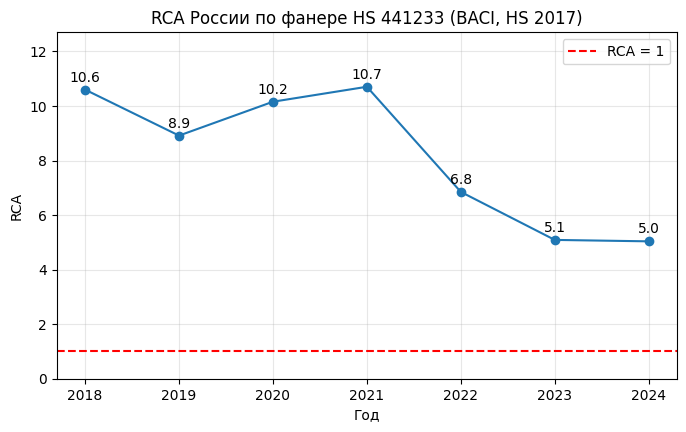

Период          2018–2024
Минимум RCA     5.04 в 2024 году
Максимум RCA    10.70 в 2021 году
Лет с RCA ≥ 1   7 из 7

2021 -> 2024: доля в экспорте России 0.377% -> 0.149%, доля в мире 0.035% -> 0.030%


In [6]:
rca["Доля в экспорте России, %"] = rca["X_cp"] / rca["X_c"] * 100
rca["Доля в мировом экспорте, %"] = rca["X_wp"] / rca["X_w"] * 100
display(rca[["Year", "Доля в экспорте России, %", "Доля в мировом экспорте, %", "RCA"]])

min_row = rca.loc[rca["RCA"].idxmin()]
max_row = rca.loc[rca["RCA"].idxmax()]
years_above = rca.loc[rca["RCA"] >= 1, "Year"].tolist()

plt.figure(figsize=(8, 4.5))
plt.plot(rca["Year"], rca["RCA"], marker="o")
for _, r in rca.iterrows():
    plt.text(r["Year"], r["RCA"] + 0.3, f"{r['RCA']:.1f}", ha="center")
plt.axhline(1, color="red", ls="--", label="RCA = 1")
plt.title("RCA России по фанере HS 441233 (BACI, HS 2017)")
plt.xlabel("Год")
plt.ylabel("RCA")
plt.xticks(rca["Year"])
plt.ylim(0, rca["RCA"].max() + 2)
plt.grid(alpha=0.3)
plt.legend()
plt.show()

print(f"Период          {rca['Year'].min()}–{rca['Year'].max()}")
print(f"Минимум RCA     {min_row['RCA']:.2f} в {int(min_row['Year'])} году")
print(f"Максимум RCA    {max_row['RCA']:.2f} в {int(max_row['Year'])} году")
print(f"Лет с RCA ≥ 1   {len(years_above)} из {len(rca)}")

# Что сильнее сдвинуло RCA с 2021 по 2024: доля фанеры у России или доля фанеры в мире
r21 = rca[rca["Year"] == 2021].iloc[0]
r24 = rca[rca["Year"] == 2024].iloc[0]
print()
print(f"2021 -> 2024: доля в экспорте России {r21['Доля в экспорте России, %']:.3f}% -> {r24['Доля в экспорте России, %']:.3f}%,"
      f" доля в мире {r21['Доля в мировом экспорте, %']:.3f}% -> {r24['Доля в мировом экспорте, %']:.3f}%")

**[Красный, 1 балл]**

## Пункт 2в. Концентрация экспортной корзины

Загрузи российский экспорт по группам HS2 за последний год. Рассчитай HHI, энтропию Шеннона и нормированную энтропию. Затем увеличь стоимость экспорта крупнейшей группы на 25%. Пересчитай доли так, чтобы их сумма снова равнялась единице. Затем заново вычисли показатели.

**Что должно получиться.** Таблица крупнейших групп и сравнение исходного распределения со сценарием.

**Пример вывода**

```text
Крупнейшая доля              ...%
HHI             ... → ...
Энтропия        ... → ...
Норм. энтропия  ... → ...
Сумма долей     ... → ...
```

In [7]:
hs2, url_hs2 = load_oec(trade_cube, ["HS2 Official"], ["Trade Value"],
                        [f"Exporter Country Official:{country_id}", f"Year:{last_year}"])
hs2 = hs2[hs2["Trade Value"] > 0].copy()
hs2 = hs2.sort_values("Trade Value", ascending=False).reset_index(drop=True)
hs2["share"] = hs2["Trade Value"] / hs2["Trade Value"].sum()


def concentration(shares):
    hhi = (shares ** 2).sum()
    entropy = -(shares * np.log(shares)).sum()  # натуральный логарифм
    entropy_norm = entropy / np.log(len(shares))
    return hhi, entropy, entropy_norm


top_hs2 = hs2.head(10).copy()
top_hs2["Экспорт, млрд долл."] = top_hs2["Trade Value"] / 1e9
top_hs2["Доля, %"] = top_hs2["share"] * 100
display(top_hs2[["HS2 Official ID", "HS2 Official", "Экспорт, млрд долл.", "Доля, %"]])

hhi_0, h_0, hn_0 = concentration(hs2["share"])

# Сценарий: экспорт крупнейшей группы +25%, остальные без изменений, доли считаем заново
scenario_value = hs2["Trade Value"].copy()
scenario_value.iloc[0] = scenario_value.iloc[0] * 1.25
scenario_share = scenario_value / scenario_value.sum()
hhi_1, h_1, hn_1 = concentration(scenario_share)

print(f"Год {last_year}, групп HS2 с ненулевым экспортом: {len(hs2)}")
print(f"Крупнейшая группа: {hs2.loc[0, 'HS2 Official ID']} {hs2.loc[0, 'HS2 Official']}")
print(f"Крупнейшая доля              {hs2.loc[0, 'share'] * 100:.1f}% -> {scenario_share.iloc[0] * 100:.1f}%")
print(f"HHI             {hhi_0:.3f} -> {hhi_1:.3f}  ({(hhi_1 / hhi_0 - 1) * 100:+.1f}%)")
print(f"Энтропия        {h_0:.3f} -> {h_1:.3f}  ({(h_1 / h_0 - 1) * 100:+.1f}%)")
print(f"Норм. энтропия  {hn_0:.3f} -> {hn_1:.3f}")
print(f"Сумма долей     {hs2['share'].sum():.3f} -> {scenario_share.sum():.3f}")
print()
share_44 = hs2.loc[hs2["HS2 Official ID"].astype(str) == "44", "share"].sum()
print(f"Для сравнения: вся древесина HS 44 даёт {share_44:.1%} экспорта России, фанера 441233 - {row_last['X_cp'] / row_last['X_c']:.2%}")
print("Запрос:", url_hs2)

,HS2 Official ID,HS2 Official,"Экспорт, млрд долл.","Доля, %"
0,27,"Mineral Fuels, Oils, Waxes, and its Distillate...",235.427,62.496
1,71,"Precious stones, metals, & pearls",18.818,4.995
2,31,Fertilizers,15.115,4.012
3,72,Iron & steel,12.511,3.321
4,10,Cereals,10.867,2.885
5,76,Aluminum articles,7.906,2.099
6,15,"Animal or vegetable fats, oils, & waxes",6.477,1.719
7,26,"Ores, Slag and Ash",6.056,1.608
8,03,"Fish, Crustaceans & Molluscs",5.745,1.525
9,44,"Wood, wood articles, & charcoal",5.739,1.523


Год 2024, групп HS2 с ненулевым экспортом: 96
Крупнейшая группа: 27 Mineral Fuels, Oils, Waxes, and its Distillated Derivatives
Крупнейшая доля              62.5% -> 67.6%
HHI             0.399 -> 0.463  (+16.0%)
Энтропия        1.887 -> 1.690  (-10.4%)
Норм. энтропия  0.413 -> 0.370
Сумма долей     1.000 -> 1.000

Для сравнения: вся древесина HS 44 даёт 1.5% экспорта России, фанера 441233 - 0.15%
Запрос: https://api-v2.oec.world/tesseract/data.jsonrecords?cube=trade_i_baci_a_17&drilldowns=HS2+Official&measures=Trade+Value&locale=en&include=Exporter+Country+Official%3Arus%3BYear%3A2024


**[Красный, 1 балл]**

## Пункт 2г. ECI страны и PCI товара

Загрузи ECI страны и PCI товара из наборов данных OEC для HS17 на уровне HS6. Выбери год, который есть и в торговых данных, и в данных о сложности. Не смешивай показатель страны с показателем товара.

**Что должно получиться.** Сопоставимая таблица ECI и PCI с годом и ссылками на запросы.

**Пример вывода**

```text
Год          ...
ECI страны    ...
PCI товара    ...
Объекты       страна и товар
```

In [8]:
eci_cube = "complexity_eci_a_hs17_hs6"
pci_cube = "complexity_pci_a_hs17_hs6"

eci_rus, url_eci = load_oec(eci_cube, ["Year"], ["ECI"], [f"Country Official:{country_id}"])
pci_prod, url_pci = load_oec(pci_cube, ["Year"], ["PCI"], [f"HS6 Official:{product_id}"])

complexity = eci_rus.merge(pci_prod, on="Year")
display(complexity)

# Год, который есть и в торговых данных, и в данных о сложности
common_years = sorted(set(complexity["Year"]) & set(rca["Year"]))
year_cmp = max(common_years)
eci_value = complexity.loc[complexity["Year"] == year_cmp, "ECI"].iloc[0]
pci_value = complexity.loc[complexity["Year"] == year_cmp, "PCI"].iloc[0]

# Чтобы понимать масштаб, смотрим места среди всех стран и всех товаров того же года
eci_year, url_eci_year = load_oec(eci_cube, ["Country Official"], ["ECI"], [f"Year:{year_cmp}"])
pci_year, url_pci_year = load_oec(pci_cube, ["HS6 Official"], ["PCI"], [f"Year:{year_cmp}"])
eci_place = (eci_year["ECI"] > eci_value).sum() + 1
pci_place = (pci_year["PCI"] > pci_value).sum() + 1

print(f"Год          {year_cmp}")
print(f"ECI страны    {eci_value:.3f}  (место {eci_place} из {len(eci_year)} стран)")
print(f"PCI товара    {pci_value:.3f}  (место {pci_place} из {len(pci_year)} товаров HS6)")
print("Объекты       ECI - Россия целиком, PCI - товар 441233")
print("Версия        HS 2017, уровень HS6 (OEC Complexity)")
print()
print("Запросы:")
print(url_eci)
print(url_pci)

,Year,ECI,PCI
0,2018,0.801,-0.544
1,2019,0.805,-0.728
2,2020,0.739,-0.765
3,2021,0.647,-0.724
4,2022,0.618,-0.683
5,2023,0.494,-0.767
6,2024,0.302,-0.715


Год          2024
ECI страны    0.302  (место 48 из 130 стран)
PCI товара    -0.715  (место 3303 из 4406 товаров HS6)
Объекты       ECI - Россия целиком, PCI - товар 441233
Версия        HS 2017, уровень HS6 (OEC Complexity)

Запросы:
https://api-v2.oec.world/tesseract/data.jsonrecords?cube=complexity_eci_a_hs17_hs6&drilldowns=Year&measures=ECI&locale=en&include=Country+Official%3Arus
https://api-v2.oec.world/tesseract/data.jsonrecords?cube=complexity_pci_a_hs17_hs6&drilldowns=Year&measures=PCI&locale=en&include=HS6+Official%3A441233


**[Чёрный, 1 балл]**

## Пункт 3а. Страны с RCA не ниже единицы

Для последнего года рассчитай RCA выбранного товара у всех экспортёров. Отбери страны с $RCA\geq1$. Добавь их ECI за тот же год. Покажи крупнейших экспортёров товара среди отобранных стран.

**Что должно получиться.** Таблица со страной, стоимостью экспорта товара, RCA и ECI.

**Пример вывода**

```text
Страна        Экспорт, млн долл.   RCA    ECI
[страна 1]                   ...   ...    ...
[страна 2]                   ...   ...    ...
[страна 3]                   ...   ...    ...
```

Проверка: сумма по странам 6.767 млрд, мировой экспорт товара 6.767 млрд
Стран с RCA ≥ 1 в 2024: 20 из 112, они дают 85.5% мирового экспорта товара
Из них без ECI в наборе OEC за 2024: Latvia, Estonia, Curaçao


,Страна,"Экспорт, млн долл.","Доля в мире, %",RCA,ECI
17,China,"2,785.709",41.167,2.620,1.063
88,Russia,561.714,8.301,5.037,0.302
110,Vietnam,499.956,7.388,3.343,-0.058
65,Latvia,361.397,5.341,63.014,NaN
31,Finland,287.748,4.252,12.128,1.488
45,Indonesia,231.804,3.426,2.638,-0.110
57,Cambodia,225.394,3.331,19.697,-0.704
84,Poland,192.835,2.850,1.824,0.987
29,Spain,174.176,2.574,1.482,0.784
30,Estonia,153.490,2.268,25.801,NaN


ECI у 10 крупнейших из них (есть у 8): от -0.70 до 1.49, медиана 0.54
Медиана ECI всех стран в 2024: -0.07


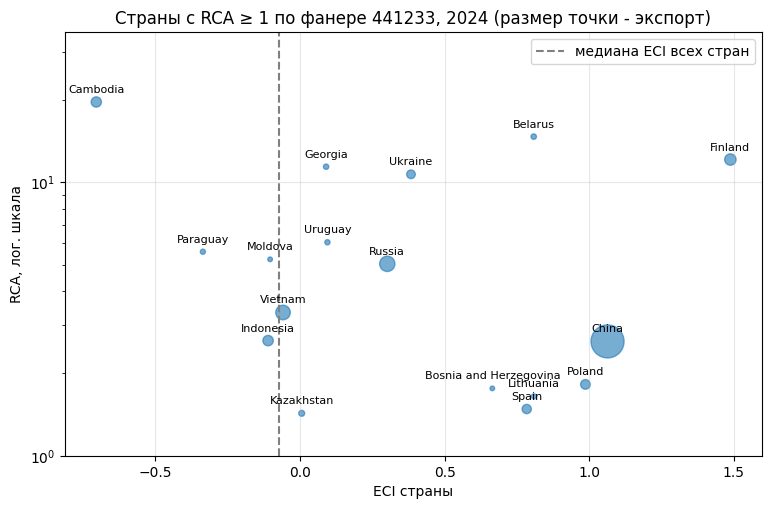

In [9]:
exp_prod, url_exp_prod = load_oec(trade_cube, ["Exporter Country Official"], ["Trade Value"],
                                  [f"HS6 Official:{product_id}", f"Year:{last_year}"])
exp_total, url_exp_total = load_oec(trade_cube, ["Exporter Country Official"], ["Trade Value"], [f"Year:{last_year}"])

countries = exp_prod.rename(columns={"Trade Value": "X_cp"})
countries = countries.merge(exp_total.rename(columns={"Trade Value": "X_c"}),
                            on=["Exporter Country Official ID", "Exporter Country Official"])

world_prod = row_last["X_wp"]
world_total = row_last["X_w"]
print(f"Проверка: сумма по странам {countries['X_cp'].sum() / 1e9:.3f} млрд, мировой экспорт товара {world_prod / 1e9:.3f} млрд")

countries["RCA"] = (countries["X_cp"] / countries["X_c"]) / (world_prod / world_total)

eci_for_merge = eci_year.rename(columns={"Country Official ID": "Exporter Country Official ID"})
countries = countries.merge(eci_for_merge[["Exporter Country Official ID", "ECI"]],
                            on="Exporter Country Official ID", how="left")

rca_ge1 = countries[countries["RCA"] >= 1].sort_values("X_cp", ascending=False).copy()
rca_ge1["Экспорт, млн долл."] = rca_ge1["X_cp"] / 1e6
rca_ge1["Доля в мире, %"] = rca_ge1["X_cp"] / world_prod * 100
rca_ge1 = rca_ge1.rename(columns={"Exporter Country Official": "Страна"})

print(f"Стран с RCA ≥ 1 в {last_year}: {len(rca_ge1)} из {len(countries)}, они дают {rca_ge1['X_cp'].sum() / world_prod:.1%} мирового экспорта товара")
no_eci = rca_ge1.loc[rca_ge1["ECI"].isna(), "Страна"].tolist()
print(f"Из них без ECI в наборе OEC за {year_cmp}: {', '.join(no_eci)}")
display(rca_ge1[["Страна", "Экспорт, млн долл.", "Доля в мире, %", "RCA", "ECI"]].head(15))

top10 = rca_ge1.head(10)
print(f"ECI у 10 крупнейших из них (есть у {top10['ECI'].notna().sum()}): от {top10['ECI'].min():.2f} до {top10['ECI'].max():.2f}, медиана {top10['ECI'].median():.2f}")
print(f"Медиана ECI всех стран в {year_cmp}: {eci_year['ECI'].median():.2f}")

with_eci = rca_ge1.dropna(subset=["ECI"])
plt.figure(figsize=(9, 5.5))
plt.scatter(with_eci["ECI"], with_eci["RCA"], s=with_eci["Экспорт, млн долл."] / 5 + 10, alpha=0.6)
for _, r in with_eci.iterrows():
    plt.text(r["ECI"], r["RCA"] * 1.08, r["Страна"], fontsize=8, ha="center")
plt.ylim(1, with_eci["RCA"].max() * 1.8)
plt.axvline(eci_year["ECI"].median(), color="gray", ls="--", label="медиана ECI всех стран")
plt.yscale("log")
plt.title(f"Страны с RCA ≥ 1 по фанере 441233, {last_year} (размер точки - экспорт)")
plt.xlabel("ECI страны")
plt.ylabel("RCA, лог. шкала")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

**[Чёрный, 1 балл]**

## Пункт 3б. Итоговая сводка по стране и товару

Собери в одну таблицу RCA, долю товара в экспорте страны, HHI, нормированную энтропию, ECI и PCI. Укажи годы и источники. На основе сводки охарактеризуй роль товара. Он может быть выраженной специализацией, источником диверсификации или нишевым направлением.

**Что должно получиться.** Одна строка с показателями и чёткий итоговый вывод.

**Пример вывода**

```text
RCA ... | доля ...% | HHI ... | Hнорм ...
ECI ... | PCI ...
Вывод  ...
```

In [10]:
summary = pd.DataFrame([{
    "Страна": "Россия",
    "Товар": "441233 (HS 2017)",
    "RCA": row_last["RCA"],
    "Доля в экспорте, %": row_last["X_cp"] / row_last["X_c"] * 100,
    "HHI (HS2)": hhi_0,
    "Hнорм (HS2)": hn_0,
    "ECI": eci_value,
    "PCI": pci_value,
    "Год": last_year,
    "Источник": "BACI HS17 и OEC Complexity HS17 HS6 через API OEC",
}])
display(summary)

print(f"RCA {row_last['RCA']:.2f} | доля {row_last['X_cp'] / row_last['X_c'] * 100:.2f}% | HHI {hhi_0:.3f} | Hнорм {hn_0:.3f}")
print(f"ECI {eci_value:.3f} | PCI {pci_value:.3f}  (все показатели за {last_year} год)")
print("Вывод  выраженная специализация: RCA выше 1 во все годы. Но доля в экспорте маленькая,")
print("       на концентрацию корзины почти не влияет, а PCI ниже нуля и ниже ECI России,")
print("       так что усложнения экспорта этот товар не даёт")

,Страна,Товар,RCA,"Доля в экспорте, %",HHI (HS2),Hнорм (HS2),ECI,PCI,Год,Источник
0,Россия,441233 (HS 2017),5.037,0.149,0.399,0.413,0.302,-0.715,2024,BACI HS17 и OEC Complexity HS17 HS6 через API OEC


RCA 5.04 | доля 0.15% | HHI 0.399 | Hнорм 0.413
ECI 0.302 | PCI -0.715  (все показатели за 2024 год)
Вывод  выраженная специализация: RCA выше 1 во все годы. Но доля в экспорте маленькая,
       на концентрацию корзины почти не влияет, а PCI ниже нуля и ниже ECI России,
       так что усложнения экспорта этот товар не даёт


**[Чёрный, 1 балл]**

## Пункт 3в. Ограничения и следующие шаги

Составь таблицу не менее чем из трёх строк. В первой колонке укажи ограничение данных или метода. Во второй предложи проверку, которая способна изменить итоговое решение. Не интерпретируй RCA, ECI или PCI как оценки причинного эффекта.

**Что должно получиться.** Проверяемый план следующего этапа.

**Пример вывода**

```text
[ограничение 1] → [проверка, которая отвечает на это ограничение]
[ограничение 2] → [источник или показатель для проверки]
[ограничение 3] → [условие пересмотра вывода]
```

In [11]:
limits = pd.DataFrame({
    "Ограничение": [
        "После 2022 года экспорт России в BACI восстановлен по импорту партнёров, часть стран (Иран, ОАЭ и др.) не отчитывается",
        "Код 441233 смешивает берёзовую фанеру с тополиной и эвкалиптовой, в мировой экспорт входит дешёвая фанера Китая и Вьетнама",
        "RCA описывает только структуру экспорта, а падение 2022–2024 могли дать санкции, а не конкурентоспособность",
        "ECI и PCI рассчитаны по одной версии HS и одному году и тоже опираются на зеркальные данные",
    ],
    "Проверка": [
        "Сверить экспорт 441233 с UN Comtrade и данными ФТС за 2021 и с отраслевыми оценками за 2023–2024",
        "Посчитать RCA для всей 4412 и сравнить цену за тонну у России, Финляндии, Латвии и Китая",
        "Посмотреть долю России в импорте фанеры Китая, Египта, Кореи и Турции до и после 2022 года",
        "Повторить ECI и PCI в HS 2012 и за 2021 год, посмотреть, сохраняется ли знак и порядок",
    ],
    "Когда пересмотрим вывод": [
        "Если с недостающими странами доля 441233 в экспорте России меняется настолько, что RCA падает ниже 2",
        "Если по 4412 RCA близок к 1 или цена России не выше, чем у Китая",
        "Если и на этих рынках доля России падает, специализация слабеет не только из-за санкций",
        "Если в другой версии PCI товара выше ECI страны, вывод про простоту товара не держится",
    ],
})
pd.set_option("display.max_colwidth", 140)
display(limits)

,Ограничение,Проверка,Когда пересмотрим вывод
0,"После 2022 года экспорт России в BACI восстановлен по импорту партнёров, часть стран (Иран, ОАЭ и др.) не отчитывается",Сверить экспорт 441233 с UN Comtrade и данными ФТС за 2021 и с отраслевыми оценками за 2023–2024,"Если с недостающими странами доля 441233 в экспорте России меняется настолько, что RCA падает ниже 2"
1,"Код 441233 смешивает берёзовую фанеру с тополиной и эвкалиптовой, в мировой экспорт входит дешёвая фанера Китая и Вьетнама","Посчитать RCA для всей 4412 и сравнить цену за тонну у России, Финляндии, Латвии и Китая","Если по 4412 RCA близок к 1 или цена России не выше, чем у Китая"
2,"RCA описывает только структуру экспорта, а падение 2022–2024 могли дать санкции, а не конкурентоспособность","Посмотреть долю России в импорте фанеры Китая, Египта, Кореи и Турции до и после 2022 года","Если и на этих рынках доля России падает, специализация слабеет не только из-за санкций"
3,ECI и PCI рассчитаны по одной версии HS и одному году и тоже опираются на зеркальные данные,"Повторить ECI и PCI в HS 2012 и за 2021 год, посмотреть, сохраняется ли знак и порядок","Если в другой версии PCI товара выше ECI страны, вывод про простоту товара не держится"


**[Чёрный, 1 бонусный балл]**

## Пункт 3г. Публикации к выводам

Выбери один или несколько выводов о RCA, концентрации, ECI или PCI. Для каждого вывода найди одну или несколько надёжных публикаций, которые помогают определить показатель или ограничить его интерпретацию. Подойдут методическое описание базы, официальный документ или рецензируемая статья. Укажи организацию или авторов, название, год, прямую ссылку и дату обращения. Одной пары «вывод — публикация» достаточно для полного бонусного балла. Если хочешь, добавь ещё. Литературный обзор делать не нужно.

**Что должно получиться.** Таблица `source_check` из одной или нескольких строк. Каждая строка связывает один вывод с одной публикацией и содержит ссылку, пояснение и границу вывода.

**Пример вывода**

```text
[вывод]  [организация или авторы, название, год]  [прямая ссылка]
[что подтверждает]  [чего не доказывает]
```

In [12]:
source_check = pd.DataFrame({
    "Вывод из блокнота": [
        f"RCA России по 441233 в {last_year} году равен {row_last['RCA']:.2f}, то есть выше 1",
        f"ECI России ({eci_value:.2f}) и PCI фанеры ({pci_value:.2f}) описывают разные объекты",
        "Экспорт России после 2022 года в BACI - зеркальная оценка",
    ],
    "Источник": [
        "Balassa B. Trade Liberalisation and 'Revealed' Comparative Advantage. The Manchester School, 1965, 33(2), 99–123",
        "Hidalgo C. A., Hausmann R. The building blocks of economic complexity. PNAS, 2009, 106(26), 10570–10575",
        "Gaulier G., Zignago S. BACI: International Trade Database at the Product-Level. CEPII Working Paper 2010-23",
    ],
    "Ссылка": [
        "https://doi.org/10.1111/j.1467-9957.1965.tb00050.x",
        "https://doi.org/10.1073/pnas.0900943106",
        "https://www.cepii.fr/PDF_PUB/wp/2010/wp2010-23.pdf",
    ],
    "Дата обращения": ["04.10.2026", "04.10.2026", "04.10.2026"],
    "Что подтверждает": [
        "RCA - отношение доли товара в экспорте страны к доле товара в мировом экспорте, порог 1 разделяет есть/нет выявленного преимущества",
        "ECI считается для страны по всей её корзине, PCI - для товара по набору стран, которые его вывозят",
        "BACI строится сверкой отчётов экспортёров и импортёров, поэтому экспорт страны можно получить и без её отчёта",
    ],
    "Чего не доказывает": [
        "Что Россия производит фанеру эффективнее или прибыльнее других",
        "Что низкий PCI фанеры или падение ECI вызваны санкциями или политикой",
        "Что для России 2022–2024 годов сверка полная, ведь часть партнёров не отчитывается",
    ],
})
display(source_check)

,Вывод из блокнота,Источник,Ссылка,Дата обращения,Что подтверждает,Чего не доказывает
0,"RCA России по 441233 в 2024 году равен 5.04, то есть выше 1","Balassa B. Trade Liberalisation and 'Revealed' Comparative Advantage. The Manchester School, 1965, 33(2), 99–123",https://doi.org/10.1111/j.1467-9957.1965.tb00050.x,04.10.2026,"RCA - отношение доли товара в экспорте страны к доле товара в мировом экспорте, порог 1 разделяет есть/нет выявленного преимущества",Что Россия производит фанеру эффективнее или прибыльнее других
1,ECI России (0.30) и PCI фанеры (-0.72) описывают разные объекты,"Hidalgo C. A., Hausmann R. The building blocks of economic complexity. PNAS, 2009, 106(26), 10570–10575",https://doi.org/10.1073/pnas.0900943106,04.10.2026,"ECI считается для страны по всей её корзине, PCI - для товара по набору стран, которые его вывозят",Что низкий PCI фанеры или падение ECI вызваны санкциями или политикой
2,Экспорт России после 2022 года в BACI - зеркальная оценка,"Gaulier G., Zignago S. BACI: International Trade Database at the Product-Level. CEPII Working Paper 2010-23",https://www.cepii.fr/PDF_PUB/wp/2010/wp2010-23.pdf,04.10.2026,"BACI строится сверкой отчётов экспортёров и импортёров, поэтому экспорт страны можно получить и без её отчёта","Что для России 2022–2024 годов сверка полная, ведь часть партнёров не отчитывается"
